In [1]:
# ==========================================
# 1. General Utilities
# ==========================================
import os
import warnings
from pathlib import Path
from datetime import datetime, timedelta
warnings.filterwarnings("ignore")
# ==========================================
# 2. Data Manipulation
# ==========================================
import pandas as pd
import numpy as np
# ==========================================
# 3. Data Visualization
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
# ==========================================
# 4. Database Connection
# ==========================================
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
# ==========================================
# 5. Data Preprocessing
# ==========================================
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
# ==========================================
# 6. Machine Learning - Regression
# ==========================================
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    IsolationForest
)
# ==========================================
# 7. Machine Learning - Classification
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
# ==========================================
# 8. Model Evaluation
# ==========================================
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score)
# ==========================================
# 9. Anomaly Detection and Clustering
# ==========================================
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor
# ==========================================
# 10. Model Saving and Loading
# ==========================================
import joblib
# ==========================================
# 11. FastAPI - Later, for API integration
# ==========================================
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
print("All SmartSpend AI libraries imported successfully!")

All SmartSpend AI libraries imported successfully!


In [2]:
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
# Find the project root containing .env
current = Path.cwd().resolve()
project_root = next(
    (p for p in [current, *current.parents] if (p / ".env").is_file()),
    None)
if project_root is None:
    raise FileNotFoundError(
        "Could not find .env. Open Jupyter from your project "
        "or update the .env path below.")
load_dotenv(project_root / ".env", override=False)
# Read database settings
database_url = os.getenv("DATABASE_URL")
if database_url:
    engine = create_engine(database_url, pool_pre_ping=True)
else:
    # Adjust these names if your .env uses different variable names.
    db_name = os.getenv("DB_NAME") or os.getenv("DB_DATABASE")
    db_user = os.getenv("DB_USER") or os.getenv("DB_USERNAME")
    db_password = os.getenv("DB_PASSWORD") or os.getenv("DB_PASS")
    db_host = os.getenv("DB_HOST", "localhost")
    db_port = os.getenv("DB_PORT", "5432")
    if not all([db_name, db_user, db_password]):
        raise ValueError(
            "Database settings missing. Check the variable names "
            "in your project's .env file.")
    db_url = URL.create(
        drivername="postgresql+psycopg2",
        username=db_user,
        password=db_password,
        host=db_host,
        port=int(db_port),
        database=db_name)
    engine = create_engine(db_url, pool_pre_ping=True)
# Test connection
with engine.connect() as connection:
    result = connection.execute(text("SELECT current_database(), version()"))
    database, version = result.fetchone()
print("PostgreSQL connected successfully!")
print("Database:", database)
print("Connection is ready for SmartSpend AI.")

PostgreSQL connected successfully!
Database: smart spend ai
Connection is ready for SmartSpend AI.


In [3]:
savings_query = text("""
    SELECT *
    FROM savings_goals
""")
with engine.connect() as connection:
    savings_goals_df = pd.read_sql(
        savings_query, connection)
print("Savings goal records:", len(savings_goals_df))
print("Columns:", savings_goals_df.columns.tolist())
display(savings_goals_df.head(10))

Savings goal records: 5
Columns: ['id', 'user_id', 'name', 'target_amount', 'current_amount', 'target_date', 'status', 'created_at', 'updated_at']


,id,user_id,name,target_amount,current_amount,target_date,status,created_at,updated_at
0,1,4,Emergency Fund,50000.0,12000.0,2027-06-30,active,2026-10-26 04:58:17.054000+00:00,2026-10-26 04:58:17.054000+00:00
1,2,4,New Laptop,70000.0,18000.0,2027-08-31,active,2026-10-26 04:58:17.062000+00:00,2026-10-26 04:58:17.062000+00:00
2,3,5,Travel Fund,40000.0,15000.0,2027-04-30,active,2026-10-26 04:58:17.068000+00:00,2026-10-26 04:58:17.068000+00:00
3,4,6,Emergency Fund,30000.0,7000.0,2027-12-31,active,2026-10-26 04:58:17.074000+00:00,2026-10-26 04:58:17.074000+00:00
4,5,7,Course Fund,25000.0,9000.0,2027-05-31,active,2026-10-26 04:58:17.080000+00:00,2026-10-26 04:58:17.080000+00:00


In [4]:
print("Missing values:")
display(savings_goals_df.isnull().sum())
print("Exact duplicate rows:",
      savings_goals_df.duplicated().sum())
if "id" in savings_goals_df.columns:
    print("Duplicate goal IDs:",
          savings_goals_df["id"].duplicated().sum())
print("\nData types:")
print(savings_goals_df.dtypes)

Missing values:


id                0
user_id           0
name              0
target_amount     0
current_amount    0
target_date       0
status            0
created_at        0
updated_at        0
dtype: int64

Exact duplicate rows: 0
Duplicate goal IDs: 0

Data types:
id                              int64
user_id                         int64
name                              str
target_amount                 float64
current_amount                float64
target_date                    object
status                            str
created_at        datetime64[us, UTC]
updated_at        datetime64[us, UTC]
dtype: object


In [5]:
print("Savings goal columns:")
for column in savings_goals_df.columns:
    print("-", column)

Savings goal columns:
- id
- user_id
- name
- target_amount
- current_amount
- target_date
- status
- created_at
- updated_at


In [6]:
# Work on a copy of the original data
savings_analysis_df = savings_goals_df.copy()
# Convert target_date to datetime
savings_analysis_df["target_date"] = pd.to_datetime(
    savings_analysis_df["target_date"],
    errors="coerce",
    utc=True)
# Calculate remaining amount and progress
savings_analysis_df["remaining_amount"] = (
    savings_analysis_df["target_amount"]
    - savings_analysis_df["current_amount"])
savings_analysis_df["progress_pct"] = (
    savings_analysis_df["current_amount"]
    / savings_analysis_df["target_amount"]
    * 100)
# Avoid negative remaining amounts for goals already achieved
savings_analysis_df["remaining_amount"] = (
    savings_analysis_df["remaining_amount"].clip(lower=0))
print("Savings goal progress calculated!")
display(
    savings_analysis_df[
        [
            "user_id",
            "name",
            "target_amount",
            "current_amount",
            "remaining_amount",
            "progress_pct",
            "target_date",
            "status"]].round(2))

Savings goal progress calculated!


,user_id,name,target_amount,current_amount,remaining_amount,progress_pct,target_date,status
0,4,Emergency Fund,50000.0,12000.0,38000.0,24.00,2027-06-30 00:00:00+00:00,active
1,4,New Laptop,70000.0,18000.0,52000.0,25.71,2027-08-31 00:00:00+00:00,active
2,5,Travel Fund,40000.0,15000.0,25000.0,37.50,2027-04-30 00:00:00+00:00,active
3,6,Emergency Fund,30000.0,7000.0,23000.0,23.33,2027-12-31 00:00:00+00:00,active
4,7,Course Fund,25000.0,9000.0,16000.0,36.00,2027-05-31 00:00:00+00:00,active


In [7]:
def classify_savings_goal(row):
    if row["current_amount"] >= row["target_amount"]:
        return "Achieved"
    elif row["progress_pct"] >= 75:
        return "On Track"
    elif row["progress_pct"] >= 25:
        return "In Progress"
    else:
        return "Needs Attention"
savings_analysis_df["goal_progress_status"] = (
    savings_analysis_df.apply(classify_savings_goal, axis=1))
display(
    savings_analysis_df[
        [
            "user_id",
            "name",
            "progress_pct",
            "remaining_amount",
            "goal_progress_status"]].round(2))


,user_id,name,progress_pct,remaining_amount,goal_progress_status
0,4,Emergency Fund,24.00,38000.0,Needs Attention
1,4,New Laptop,25.71,52000.0,In Progress
2,5,Travel Fund,37.50,25000.0,In Progress
3,6,Emergency Fund,23.33,23000.0,Needs Attention
4,7,Course Fund,36.00,16000.0,In Progress


In [8]:
# Generate simple savings recommendations
today = pd.Timestamp.now(tz="UTC").normalize()
def generate_savings_recommendation(row):
    remaining = row["remaining_amount"]
    progress = row["progress_pct"]
    target_date = row["target_date"]
    goal_name = row["name"]
    if remaining <= 0:
        return f"Congratulations! You have achieved your {goal_name} goal."
    if pd.isna(target_date):
        return (
            f"You need ₹{remaining:,.2f} more for your {goal_name}. "
            "Set a target date and a monthly savings plan.")
    days_left = (target_date.normalize() - today).days
    if days_left <= 0:
        return (
            f"Your target date for {goal_name} has passed. "
            f"Review your goal and plan for the remaining ₹{remaining:,.2f}.")
    months_left = max(days_left / 30.4375, 1 / 30.4375)
    monthly_saving_needed = remaining / months_left
    if progress < 25:
        action = "Start with a small, consistent automatic saving."
    elif progress < 75:
        action = "Keep saving consistently and review your progress monthly."
    else:
        action = "You're close to your goal; maintain your savings routine."
    return (
        f"{action} For {goal_name}, aim to save approximately "
        f"₹{monthly_saving_needed:,.2f} per month to reach your target date.")
savings_analysis_df["recommendation"] = (
    savings_analysis_df.apply(
        generate_savings_recommendation,
        axis=1))
with pd.option_context("display.max_colwidth", None):
    display(
        savings_analysis_df[
            [
                "user_id",
                "name",
                "target_date",
                "remaining_amount",
                "recommendation"]])

,user_id,name,target_date,remaining_amount,recommendation
0,4,Emergency Fund,2027-06-30 00:00:00+00:00,38000.0,"Start with a small, consistent automatic saving. For Emergency Fund, aim to save approximately ₹4,759.77 per month to reach your target date."
1,4,New Laptop,2027-08-31 00:00:00+00:00,52000.0,"Keep saving consistently and review your progress monthly. For New Laptop, aim to save approximately ₹5,189.34 per month to reach your target date."
2,5,Travel Fund,2027-04-30 00:00:00+00:00,25000.0,"Keep saving consistently and review your progress monthly. For Travel Fund, aim to save approximately ₹4,180.98 per month to reach your target date."
3,6,Emergency Fund,2027-12-31 00:00:00+00:00,23000.0,"Start with a small, consistent automatic saving. For Emergency Fund, aim to save approximately ₹1,639.49 per month to reach your target date."
4,7,Course Fund,2027-05-31 00:00:00+00:00,16000.0,"Keep saving consistently and review your progress monthly. For Course Fund, aim to save approximately ₹2,286.38 per month to reach your target date."


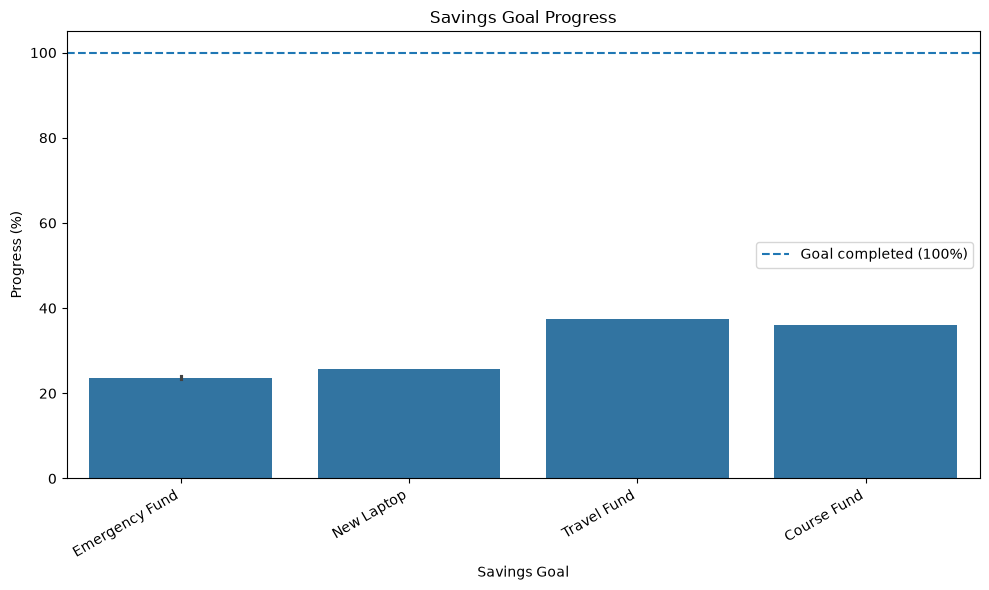

In [9]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=savings_analysis_df,
    x="name",
    y="progress_pct")
plt.axhline(
    100,
    linestyle="--",
    label="Goal completed (100%)")
plt.title("Savings Goal Progress")
plt.xlabel("Savings Goal")
plt.ylabel("Progress (%)")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
import sys
from pathlib import Path
project_root = Path.cwd()
while project_root != project_root.parent:
    if (project_root / "src" / "savings_recommendations.py").exists():
        break
    project_root = project_root.parent
module_file = project_root / "src" / "savings_recommendations.py"

if not module_file.exists():
    raise FileNotFoundError(
        "Could not find src/savings_recommendations.py")
sys.path.insert(0, str(project_root / "src"))
from savings_recommendations import analyze_savings_goals
print("Savings recommendations module imported successfully!")
savings_results_df = analyze_savings_goals(savings_goals_df)
display(
    savings_results_df[
        [
            "user_id",
            "name",
            "target_amount",
            "current_amount",
            "remaining_amount",
            "progress_pct",
            "goal_progress_status",
            "recommendation",]].round(2))

Savings recommendations module imported successfully!


,user_id,name,target_amount,current_amount,remaining_amount,progress_pct,goal_progress_status,recommendation
0,4,Emergency Fund,50000.0,12000.0,38000.0,24.00,Needs Attention,Start saving consistently. To reach Emergency ...
1,4,New Laptop,70000.0,18000.0,52000.0,25.71,In Progress,Continue saving and review progress monthly. T...
2,5,Travel Fund,40000.0,15000.0,25000.0,37.50,In Progress,Continue saving and review progress monthly. T...
3,6,Emergency Fund,30000.0,7000.0,23000.0,23.33,Needs Attention,Start saving consistently. To reach Emergency ...
4,7,Course Fund,25000.0,9000.0,16000.0,36.00,In Progress,Continue saving and review progress monthly. T...
